# Практика 1. Первый взгляд на данные

**Ситуация.** Региональный филиал оператора связи выгрузил справочник абонентов домашнего интернета
в шести городах Урала. Аналитик видит этот файл впервые. Прежде чем строить модели,
нужно понять, что в нём лежит и можно ли ему доверять.

**Задание.** Ответьте на вопросы ниже кодом, впишите числа в тест «Практика 1» в elearn,
постройте два графика и сформулируйте короткий вывод. В конце сохраните ноутбук и загрузите его в elearn.

**Файл:** `data/subscribers.csv` — 12 столбцов:

| Столбец | Смысл |
|---|---|
| `client_id` | идентификатор абонента |
| `city` | город |
| `tariff` | тариф |
| `speed_mbps` | скорость по тарифу, Мбит/с |
| `tech` | технология подключения: FTTB, xPON, ADSL |
| `monthly_fee` | ежемесячный платёж, руб. (с учётом скидок и ТВ) |
| `tv_package` | подключено ли ТВ: да / нет |
| `connected` | дата подключения |
| `traffic_gb` | трафик за последний месяц, ГБ |
| `support_calls_3m` | обращений в поддержку за 3 месяца |
| `nps` | оценка из опроса, 0–10 (не все ответили) |
| `status` | активен / расторгнут |

> Ассистентами на основе LLM пользоваться можно. Но в тест идут числа, и отвечаете за них вы:
> проверяйте, что код делает то, что вы думаете.

## Часть A. Знакомство с таблицей

Загрузите файл и посмотрите на него: первые строки, размер, типы столбцов, сводная статистика.

*Подсказка:* `pd.read_csv`, `.head()`, `.shape`, `.info()`, `.describe()`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/subscribers.csv')
df.head()

,client_id,city,tariff,speed_mbps,tech,monthly_fee,tv_package,connected,traffic_gb,support_calls_3m,nps,status
0,RT-100661,Нижний Тагил,Базовый 100,100,FTTB,745,да,2021-07-09,114.7,3,7.0,активен
1,RT-100575,Нижний Тагил,Игровой 500,500,xPON,950,нет,2018-08-05,271.7,0,7.0,активен
2,RT-101675,Екатеринбург,Базовый 100,100,FTTB,550,нет,2019-06-05,232.4,3,8.0,активен
3,RT-102333,Пермь,Игровой 500,500,FTTB,760,нет,2025-04-27,772.5,1,7.0,активен
4,RT-100470,Пермь,Семейный 300,300,xPON,1000,да,2023-08-16,860.3,0,8.0,активен


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   client_id         3000 non-null   str    
 1   city              3000 non-null   str    
 2   tariff            3000 non-null   str    
 3   speed_mbps        3000 non-null   int64  
 4   tech              3000 non-null   str    
 5   monthly_fee       3000 non-null   int64  
 6   tv_package        3000 non-null   str    
 7   connected         3000 non-null   str    
 8   traffic_gb        3000 non-null   float64
 9   support_calls_3m  3000 non-null   int64  
 10  nps               2656 non-null   float64
 11  status            3000 non-null   str    
dtypes: float64(2), int64(3), str(7)
memory usage: 514.5 KB


In [4]:
df.shape

(3000, 12)

In [3]:
df.head()

,client_id,city,tariff,speed_mbps,tech,monthly_fee,tv_package,connected,traffic_gb,support_calls_3m,nps,status
0,RT-100661,Нижний Тагил,Базовый 100,100,FTTB,745,да,2021-07-09,114.7,3,7.0,активен
1,RT-100575,Нижний Тагил,Игровой 500,500,xPON,950,нет,2018-08-05,271.7,0,7.0,активен
2,RT-101675,Екатеринбург,Базовый 100,100,FTTB,550,нет,2019-06-05,232.4,3,8.0,активен
3,RT-102333,Пермь,Игровой 500,500,FTTB,760,нет,2025-04-27,772.5,1,7.0,активен
4,RT-100470,Пермь,Семейный 300,300,xPON,1000,да,2023-08-16,860.3,0,8.0,активен


In [5]:
df.describe()

,speed_mbps,monthly_fee,traffic_gb,support_calls_3m,nps
count,3000.000000,3000.000000,3000.000000,3000.000000,2656.000000
mean,352.433333,825.959000,394.386200,0.716000,7.495482
std,280.535759,257.683037,316.576645,0.929677,1.767881
min,100.000000,440.000000,14.300000,0.000000,0.000000
25%,100.000000,550.000000,182.950000,0.000000,6.000000
50%,300.000000,760.000000,300.700000,0.000000,8.000000
75%,500.000000,1000.000000,508.925000,1.000000,9.000000
max,1000.000000,1540.000000,4161.500000,7.000000,10.000000


**Вопрос для себя:** какой тип pandas присвоил столбцу `connected`? Почему это важно, если нужно отобрать абонентов по году подключения?

## Часть B. Вопросы для теста

Каждый ответ получите кодом в отдельной ячейке. Дробные числа округляйте до одного знака после запятой.

**B1.** Сколько абонентов в Перми?

*Подсказка:* `value_counts()` или логическая маска.

In [9]:
df['city'].value_counts()['Пермь']

np.int64(586)

**B2.** Каков средний ежемесячный платёж (`monthly_fee`) абонентов на тарифе «Гигабит 1000», руб.?

*Подсказка:* сначала отберите строки, потом считайте среднее.

In [10]:
df[df['tariff'] == 'Гигабит 1000']['monthly_fee'].mean().round(1)

np.float64(1295.9)

**B3.** Какая доля абонентов подключила ТВ, в процентах?

*Подсказка:* среднее от логического столбца — это доля.

In [16]:
(df['tv_package'] == 'да').mean() * 100

np.float64(29.833333333333336)

**B4.** Сколько пропусков в столбце `nps`?

*Подсказка:* `.isna()`.

In [14]:
df['nps'].isna().sum()

np.int64(344)

**B5.** Каков медианный трафик (`traffic_gb`) у абонентов на технологии xPON, ГБ?

*Подсказка:* `.median()`.

In [17]:
df[df['tech'] == 'xPON']['traffic_gb'].median()

np.float64(323.79999999999995)

**B6.** Сколько абонентов подключились в 2025 году?

*Подсказка:* `pd.to_datetime` и `.dt.year`.

In [29]:
df[pd.to_datetime(df['connected']).dt.year == 2025].shape[0]

303

**B7.** В каком городе наибольшее среднее число обращений в поддержку?

*Подсказка:* `groupby`.

In [35]:
df.groupby('city')['support_calls_3m'].mean()

city
Екатеринбург    0.657143
Курган          1.200000
Нижний Тагил    0.802419
Пермь           0.735495
Тюмень          0.569832
Челябинск       0.678832
Name: support_calls_3m, dtype: float64

**B8.** Какая доля расторгнувших договор среди абонентов на ADSL, в процентах?

*Подсказка:* отберите ADSL, затем посчитайте долю статуса «расторгнут».

In [20]:
(df[df['tech'] == 'ADSL']['status'] == 'расторгнут').mean() * 100

np.float64(26.804123711340207)

## Часть C. Графики и вывод

**C1.** Постройте гистограмму трафика (`traffic_gb`). Подпишите оси.

**C2.** Постройте столбчатую диаграмму: доля расторгнувших договор по технологии подключения.

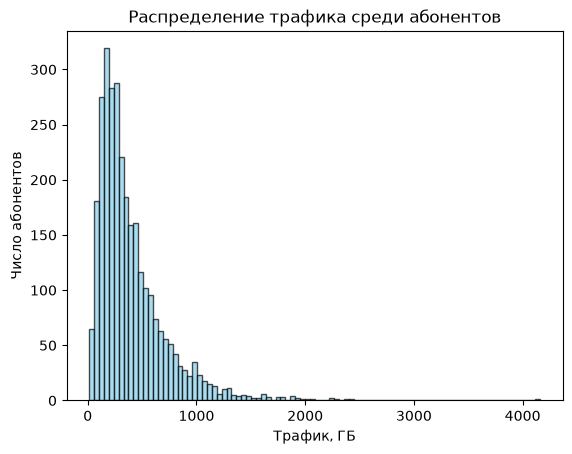

In [31]:
plt.hist(
    df['traffic_gb'],
    bins='auto',
    color='skyblue',
    edgecolor='black',
    alpha=0.7)
plt.xlabel('Трафик, ГБ')
plt.ylabel('Число абонентов')
plt.title('Распределение трафика среди абонентов')
plt.show()

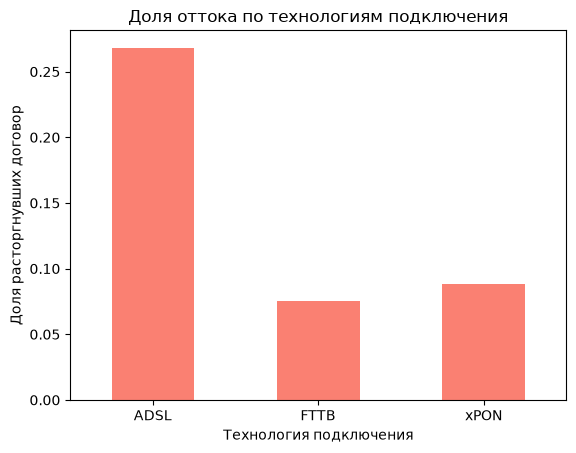

In [37]:
churn_by_tech = (df[df['status'] == 'расторгнут'].groupby('tech').size() / df.groupby('tech').size()).fillna(0)
churn_by_tech.plot(kind='bar', color='salmon')
plt.xlabel('Технология подключения')
plt.ylabel('Доля расторгнувших договор')
plt.title('Доля оттока по технологиям подключения')
plt.xticks(rotation=0)
plt.show()

**C3. Вывод.** Два-три предложения: что вы узнали из данных? Что бы вы сказали руководителю филиала? Какие вопросы к данным у вас появились?

*Ваш вывод:*

Данным нельзя доваерять! Недостаточно данных. Нужны данные за несколько месяцев.

Наибольшее количество абонентов использует в среднем 250 ГБ (цифра из графика). Медианный трафик по xPON 323. Следовательно самый популярный тариф включает от 150  до 300 ГБ. Это нулевая гипотеза.
С увеличением количества ГБ в месяц уменьшается количество пользоавтелей. Следовательно чем больше ГБ в месяц, тем менне используемым будет являться тариф.

Целевая аудитроия проайдера:
1) Люди, которые имеют ТВ и Сотовую связь и любят фильмы скачивать на локальные устройства.


344 / 2656 * 100 = 12 % пользователей не ответили на вопросы. Очень хороший показатель для статиски. Говорит о том что у провайдера отличная и отзывчивая аудитория. Вопрос в том, какую оценку в среднем они оставляли? Это не успел выяснить. 

В городе Курган наибольшее число обращений. Вопрос: из-за чего? Теряет ли бизнес деньги?